In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [2]:
# Define dataset directory
DATA_PATH = Path("C:\\Users\\NEHA KATUWAL\\Desktop\\Nepal_Agriculture_Analysis\\csv_source_files")

# Load all CSV files
datasets = {
    file.stem: pd.read_csv(file)
    for file in DATA_PATH.glob("*.csv")
}

print(f"Total datasets loaded: {len(datasets)}")

Total datasets loaded: 13


In [3]:
for name, df in datasets.items():
    print(f"{name}: {df.shape}")

01_cereal_crops_yearly: (66, 5)
02_cereal_production_by_province_2024_25: (48, 4)
03_cereal_production_by_district_2024_25: (85, 7)
04_major_cash_crops_yearly: (50, 5)
05_major_cash_crops_by_province_2024_25: (24, 6)
06_pulses_yearly: (120, 5)
07_livestock_population_yearly: (110, 3)
08_livestock_products_yearly: (150, 3)
09_major_fruits_yearly: (40, 6)
10_fresh_vegetables_yearly: (10, 4)
11_fresh_vegetables_by_province_2024_25: (7, 5)
12_chemical_fertilizer_sales_yearly: (15, 5)
13_agriculture_gdp_commodity_contribution_2024_25: (93, 2)


In [4]:
for name, df in datasets.items():
    print(f"\n{'='*60}")
    print(f"Dataset: {name}")
    print(f"Columns: {df.columns.tolist()}")
    print(df.head(3))


Dataset: 01_cereal_crops_yearly
Columns: ['Fiscal_Year', 'Crop', 'Area_Ha', 'Production_Mt', 'Yield_Mt_per_Ha']
  Fiscal_Year    Crop  Area_Ha  Production_Mt  Yield_Mt_per_Ha
0     2014/15  Barley    28053          37354             1.33
1     2015/16  Barley    28361          32801             1.16
2     2016/17  Barley    27370          30510             1.11

Dataset: 02_cereal_production_by_province_2024_25
Columns: ['Fiscal_Year', 'Province', 'Crop', 'Production_Mt']
  Fiscal_Year Province       Crop  Production_Mt
0     2024/25    Koshi  Buckwheat         4775.0
1     2024/25  Madhesh  Buckwheat            NaN
2     2024/25  Bagmati  Buckwheat         3260.0

Dataset: 03_cereal_production_by_district_2024_25
Columns: ['Fiscal_Year', 'Province', 'District', 'Area_Ha', 'Production_Mt', 'Yield_Mt_per_Ha', 'Row_Type']
  Fiscal_Year Province       District  Area_Ha  Production_Mt  \
0     2024/25    KOSHI      TAPLEJUNG    21673          63863   
1     2024/25    KOSHI  SANKHUWASABHA

In [5]:
missing_summary = pd.DataFrame({
    name: {
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Values": df.isnull().sum().sum(),
        "Duplicate Rows": df.duplicated().sum()
    }
    for name, df in datasets.items()
}).T

display(missing_summary)

,Rows,Columns,Missing Values,Duplicate Rows
01_cereal_crops_yearly,66,5,0,0
02_cereal_production_by_province_2024_25,48,4,1,0
03_cereal_production_by_district_2024_25,85,7,0,0
04_major_cash_crops_yearly,50,5,0,0
05_major_cash_crops_by_province_2024_25,24,6,0,0
06_pulses_yearly,120,5,27,0
07_livestock_population_yearly,110,3,0,0
08_livestock_products_yearly,150,3,1,0
09_major_fruits_yearly,40,6,0,0
10_fresh_vegetables_yearly,10,4,0,0


In [ ]:
# How has Nepal's cereal production changed over the last 11 fiscal years, and is production growth associated with increasing cultivated area or improving yield? 


# Select cereal production dataset
cereal_df = datasets["01_cereal_crops_yearly"]

# Aggregate production and cultivated area by fiscal year
cereal_trend = (
    cereal_df.groupby("Fiscal_Year", as_index=False)
    .agg(
        Total_Area_Ha=("Area_Ha", "sum"),
        Total_Production_Mt=("Production_Mt", "sum")
    )
)

# Calculate weighted average yield
cereal_trend["Average_Yield_Mt_per_Ha"] = (
    cereal_trend["Total_Production_Mt"] /
    cereal_trend["Total_Area_Ha"]
)

# Calculate year-over-year growth
cereal_trend["Production_Growth_%"] = (
    cereal_trend["Total_Production_Mt"].pct_change() * 100
)

cereal_trend["Area_Growth_%"] = (
    cereal_trend["Total_Area_Ha"].pct_change() * 100
)

cereal_trend["Yield_Growth_%"] = (
    cereal_trend["Average_Yield_Mt_per_Ha"].pct_change() * 100
)

# Display results
display(cereal_trend.round(2))

,Fiscal_Year,Total_Area_Ha,Total_Production_Mt,Average_Yield_Mt_per_Ha,Production_Growth_%,Area_Growth_%,Yield_Growth_%
0,2014/15,877036,5966240,6.80,NaN,NaN,NaN
1,2015/16,806316,5314284,6.59,-10.93,-8.06,-3.12
2,2016/17,1590663,9758892,6.14,83.64,97.28,-6.91
3,2017/18,1528987,10012742,6.55,2.60,-3.88,6.74
4,2018/19,850164,6385550,7.51,-36.23,-44.40,14.70
5,2019/20,1521390,10935665,7.19,71.26,78.95,-4.30
6,2020/21,2565455,11118512,4.33,1.67,68.63,-39.71
7,2021/22,1586249,10772498,6.79,-3.11,-38.17,56.70
8,2022/23,2443134,10913266,4.47,1.31,54.02,-34.22
9,2023/24,3291671,11293841,3.43,3.49,34.73,-23.19


In [7]:
# Validate reported production against area and yield

cereal_validation = cereal_df.copy()

cereal_validation["Calculated_Production"] = (
    cereal_validation["Area_Ha"] *
    cereal_validation["Yield_Mt_per_Ha"]
)

cereal_validation["Difference_%"] = (
    (
        cereal_validation["Production_Mt"] -
        cereal_validation["Calculated_Production"]
    ).abs()
    / cereal_validation["Production_Mt"].abs()
) * 100

# Flag records with more than 5% difference
cereal_validation["Data_Issue"] = (
    cereal_validation["Difference_%"] > 5
)

# Show inconsistent records
inconsistent_records = (
    cereal_validation[cereal_validation["Data_Issue"]]
    .sort_values("Difference_%", ascending=False)
)

display(
    inconsistent_records[
        [
            "Fiscal_Year",
            "Crop",
            "Area_Ha",
            "Production_Mt",
            "Yield_Mt_per_Ha",
            "Calculated_Production",
            "Difference_%"
        ]
    ].round(2)
)

print("Total inconsistent records:", len(inconsistent_records))

,Fiscal_Year,Crop,Area_Ha,Production_Mt,Yield_Mt_per_Ha,Calculated_Production,Difference_%
34,2015/16,Millet,266799,2397,1.13,301482.87,12477.51
33,2014/15,Millet,268050,8488,1.15,308257.50,3531.69
37,2018/19,Millet,263261,14225,1.19,313280.59,2102.32
15,2018/19,Wheat,3992,5665,2.85,11377.20,100.83
46,2016/17,Maize,288,2300121,2.55,734.40,99.97
52,2022/23,Maize,40256,2976490,3.17,127611.52,95.71
47,2017/18,Maize,54158,2555847,2.68,145143.44,94.32
49,2019/20,Maize,57650,2835674,2.96,170644.00,93.98
50,2020/21,Maize,79776,2997733,3.06,244114.56,91.86
51,2021/22,Maize,85565,3106397,3.15,269529.75,91.32


Total inconsistent records: 21


In [8]:
# Inspect original records
display(cereal_df.head(15))

,Fiscal_Year,Crop,Area_Ha,Production_Mt,Yield_Mt_per_Ha
0,2014/15,Barley,28053,37354,1.33
1,2015/16,Barley,28361,32801,1.16
2,2016/17,Barley,27370,30510,1.11
3,2017/18,Barley,24648,30510,1.24
4,2018/19,Barley,24409,30550,1.25
5,2019/20,Barley,24404,31147,1.28
6,2020/21,Barley,21862,29433,1.35
7,2021/22,Barley,23134,32156,1.39
8,2022/23,Barley,17536,25912,1.48
9,2023/24,Barley,18599,24931,1.34


In [9]:
# Inspect numerical statistics
display(cereal_df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Area_Ha,66.0,3.078871e+05,3.929246e+05,288.00,22180.0000,88574.000,4.754198e+05,1473474.00
Production_Mt,66.0,1.576949e+06,1.980295e+06,2397.00,25176.2500,317470.000,2.765717e+06,5955476.00
Yield_Mt_per_Ha,66.0,2.186515e+00,1.025886e+00,1.01,1.2325,1.905,3.047500e+00,4.19


In [11]:
# Summarize validation issues by crop

crop_issue_summary = (
    cereal_validation
    .groupby("Crop")
    .agg(
        Total_Records=("Crop", "size"),
        Inconsistent_Records=("Data_Issue", "sum"),
        Average_Difference_Pct=("Difference_%", "mean")
    )
    .reset_index()
)

crop_issue_summary["Issue_Rate_%"] = (
    crop_issue_summary["Inconsistent_Records"] /
    crop_issue_summary["Total_Records"] * 100
)

display(crop_issue_summary.round(2))

,Crop,Total_Records,Inconsistent_Records,Average_Difference_Pct,Issue_Rate_%
0,Barley,11,0,0.19,0.00
1,Buckwheat,11,0,0.25,0.00
2,Maize,11,8,62.16,72.73
3,Millet,11,3,1646.64,27.27
4,Paddy,11,7,43.60,63.64
5,Wheat,11,3,24.60,27.27


In [12]:
# Display all inconsistent crop-year records

display(
    inconsistent_records[
        [
            "Fiscal_Year",
            "Crop",
            "Area_Ha",
            "Production_Mt",
            "Yield_Mt_per_Ha",
            "Calculated_Production",
            "Difference_%"
        ]
    ].sort_values(["Crop", "Fiscal_Year"])
)

,Fiscal_Year,Crop,Area_Ha,Production_Mt,Yield_Mt_per_Ha,Calculated_Production,Difference_%
44,2014/15,Maize,82395,145291,2.43,200219.85,37.806093
46,2016/17,Maize,288,2300121,2.55,734.40,99.968071
47,2017/18,Maize,54158,2555847,2.68,145143.44,94.321122
48,2018/19,Maize,56447,713635,2.84,160309.48,77.536208
49,2019/20,Maize,57650,2835674,2.96,170644.00,93.982242
50,2020/21,Maize,79776,2997733,3.06,244114.56,91.856694
51,2021/22,Maize,85565,3106397,3.15,269529.75,91.323397
52,2022/23,Maize,40256,2976490,3.17,127611.52,95.712684
33,2014/15,Millet,268050,8488,1.15,308257.50,3531.685910
34,2015/16,Millet,266799,2397,1.13,301482.87,12477.508135


In [13]:
# Calculate production-to-calculated-production ratio

cereal_validation["Production_Ratio"] = (
    cereal_validation["Production_Mt"] /
    cereal_validation["Calculated_Production"]
)

ratio_summary = (
    cereal_validation
    .groupby("Crop")
    .agg(
        Median_Ratio=("Production_Ratio", "median"),
        Minimum_Ratio=("Production_Ratio", "min"),
        Maximum_Ratio=("Production_Ratio", "max"),
        Records=("Production_Ratio", "count")
    )
    .round(2)
)

display(ratio_summary)

,Median_Ratio,Minimum_Ratio,Maximum_Ratio,Records
Crop,,,,
Barley,1.00,1.00,1.00,11
Buckwheat,1.00,0.99,1.00,11
Maize,11.53,0.73,3131.97,11
Millet,1.00,0.01,1.00,11
Paddy,3.03,1.00,3.76,11
Wheat,1.00,0.50,6.90,11


In [14]:
# Calculate total production by crop

crop_production = (
    cereal_df.groupby("Crop")
    .agg(
        Total_Production_Mt=("Production_Mt", "sum"),
        Average_Production_Mt=("Production_Mt", "mean"),
        Total_Records=("Production_Mt", "count")
    )
    .reset_index()
)

# Calculate contribution percentage
crop_production["Production_Share_%"] = (
    crop_production["Total_Production_Mt"]
    / crop_production["Total_Production_Mt"].sum()
) * 100

# Rank crops by production
crop_production = crop_production.sort_values(
    "Total_Production_Mt",
    ascending=False
).reset_index(drop=True)

crop_production.insert(
    0, "Rank", range(1, len(crop_production) + 1)
)

display(crop_production.round(2))

,Rank,Crop,Total_Production_Mt,Average_Production_Mt,Total_Records,Production_Share_%
0,1,Paddy,58549349,5322668.09,11,56.25
1,2,Maize,24332166,2212015.09,11,23.38
2,3,Wheat,18193296,1653936.00,11,17.48
3,4,Millet,2528590,229871.82,11,2.43
4,5,Barley,327558,29778.00,11,0.31
5,6,Buckwheat,147652,13422.91,11,0.14


In [15]:
# Annual production comparison by crop

annual_crop_production = (
    cereal_df.pivot_table(
        index="Fiscal_Year",
        columns="Crop",
        values="Production_Mt",
        aggfunc="sum"
    )
)

display(annual_crop_production.round(2))

Crop,Barley,Buckwheat,Maize,Millet,Paddy,Wheat
Fiscal_Year,,,,,,
2014/15,37354,10870,145291,8488,4788612,975625
2015/16,32801,11641,231517,2397,4299079,736849
2016/17,30510,12039,2300121,306704,5230327,1879191
2017/18,30510,11472,2555847,313987,5151925,1949001
2018/19,30550,11464,713635,14225,5610011,5665
2019/20,31147,11724,2835674,320953,5550878,2185289
2020/21,29433,15917,2997733,326443,5621710,2127276
2021/22,32156,19290,3106397,339462,5130625,2144568
2022/23,25912,15083,2976490,310847,5486472,2098462


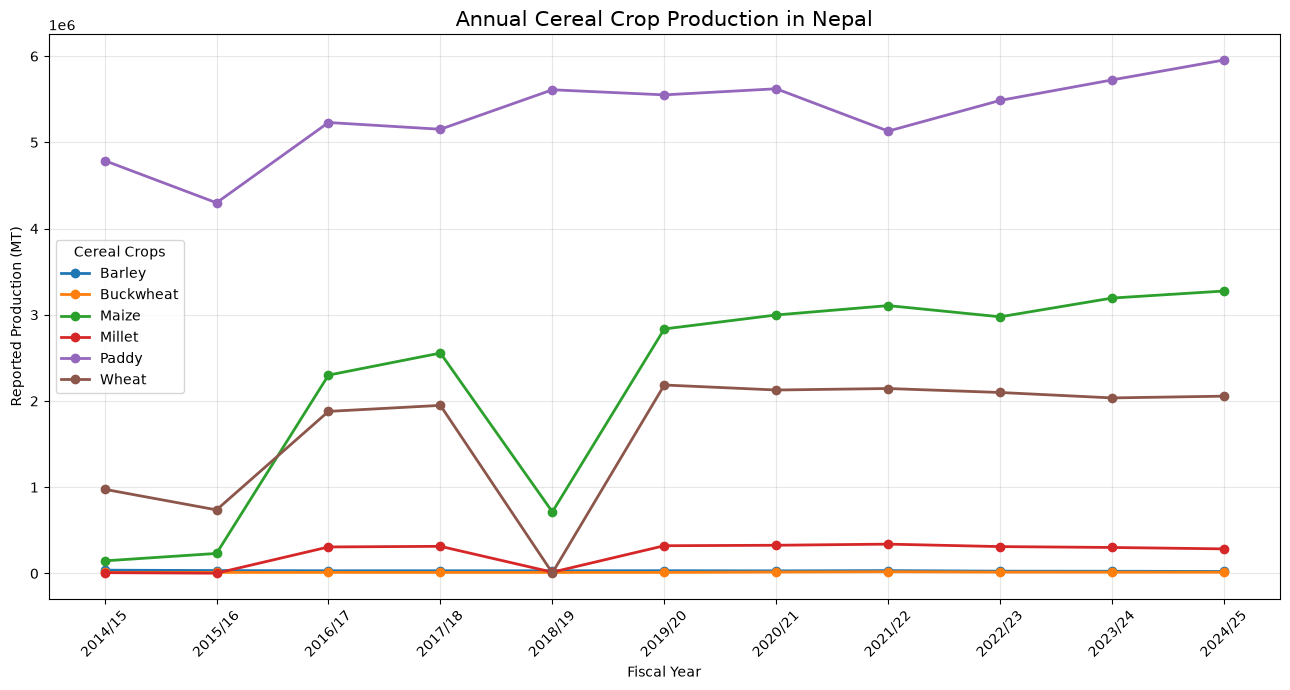

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(13, 7))

for crop in annual_crop_production.columns:
    plt.plot(
        annual_crop_production.index,
        annual_crop_production[crop],
        marker="o",
        linewidth=2,
        label=crop
    )

plt.title("Annual Cereal Crop Production in Nepal", fontsize=15)
plt.xlabel("Fiscal Year")
plt.ylabel("Reported Production (MT)")
plt.xticks(rotation=45)
plt.legend(title="Cereal Crops")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()